Downloaded dataset.
Shape: (101766, 50)

Target distribution:
 readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

SQL 1 - Readmission split:
   readmitted  patients    pct
0        <30     11357  11.16
1        >30     35545  34.93
2         NO     54864  53.91

SQL 2 - Readmission rate by age group:
         age  total  readmitted_30  rate_pct
0    [0-10)    161              3      1.86
1   [10-20)    691             40      5.79
2   [20-30)   1657            236     14.24
3   [30-40)   3775            424     11.23
4   [40-50)   9685           1027     10.60
5   [50-60)  17256           1668      9.67
6   [60-70)  22483           2502     11.13
7   [70-80)  26068           3069     11.77
8   [80-90)  17197           2078     12.08
9  [90-100)   2793            310     11.10

SQL 3 - Readmission rate by prior inpatient visits:
    prior_inpatient_visits  total  rate_pct
0                       0  67630      8.44
1                       1  19521     12.92
2   

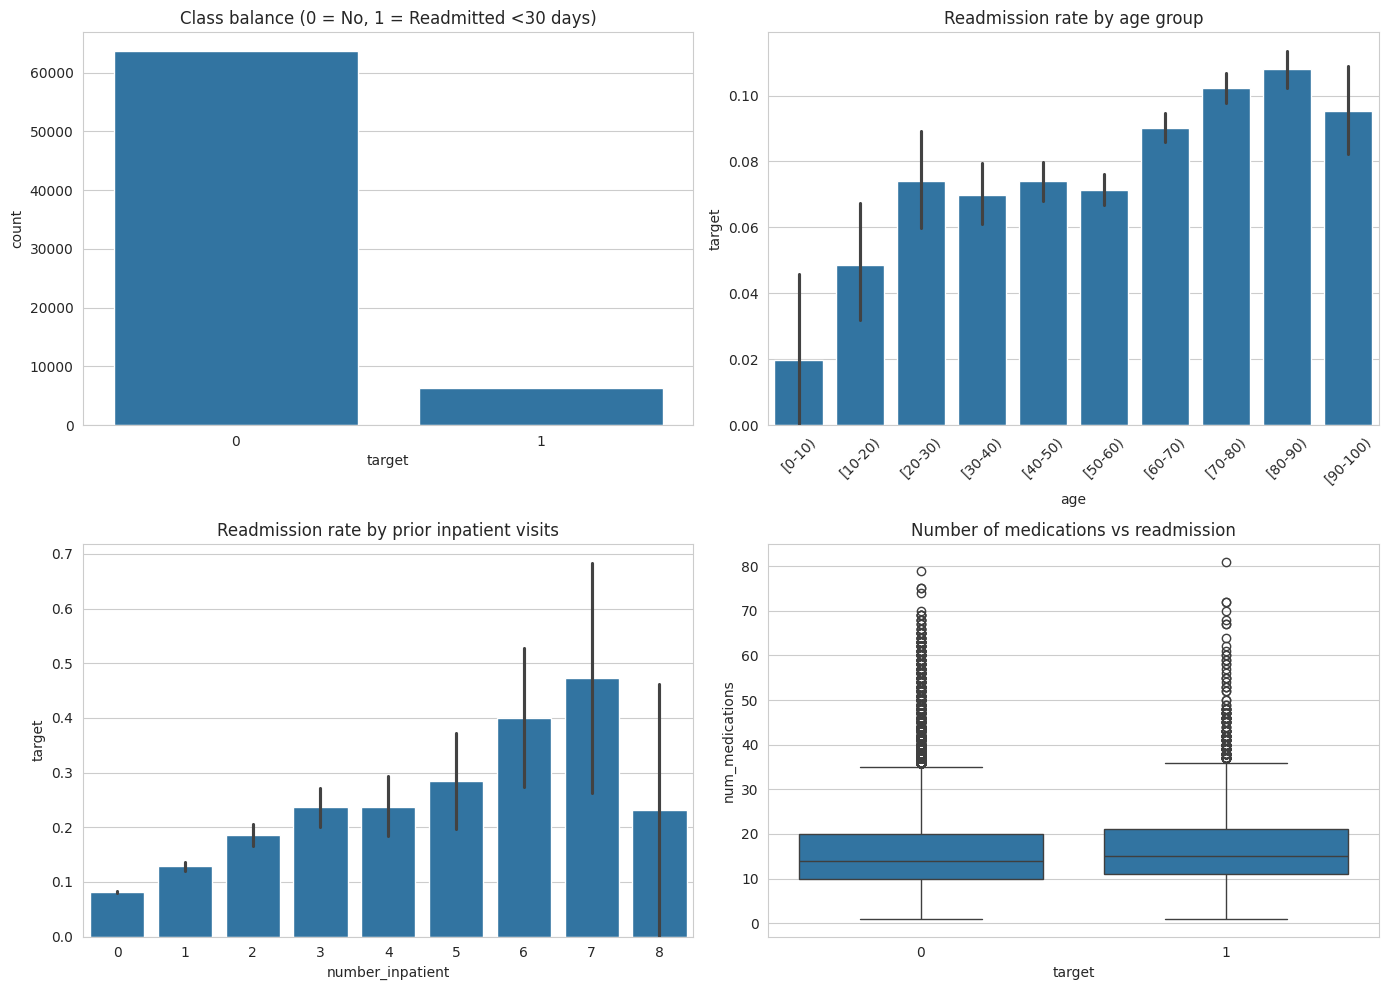


Feature matrix shape: (69987, 112)
Train: (55989, 112) | Test: (13998, 112)

Logistic Regression | ROC-AUC: 0.648
                 precision    recall  f1-score   support

 Not readmitted       0.93      0.69      0.79     12741
Readmitted <30d       0.14      0.51      0.22      1257

       accuracy                           0.67     13998
      macro avg       0.54      0.60      0.51     13998
   weighted avg       0.86      0.67      0.74     13998


Random Forest | ROC-AUC: 0.639
                 precision    recall  f1-score   support

 Not readmitted       0.92      0.95      0.94     12741
Readmitted <30d       0.25      0.17      0.20      1257

       accuracy                           0.88     13998
      macro avg       0.58      0.56      0.57     13998
   weighted avg       0.86      0.88      0.87     13998



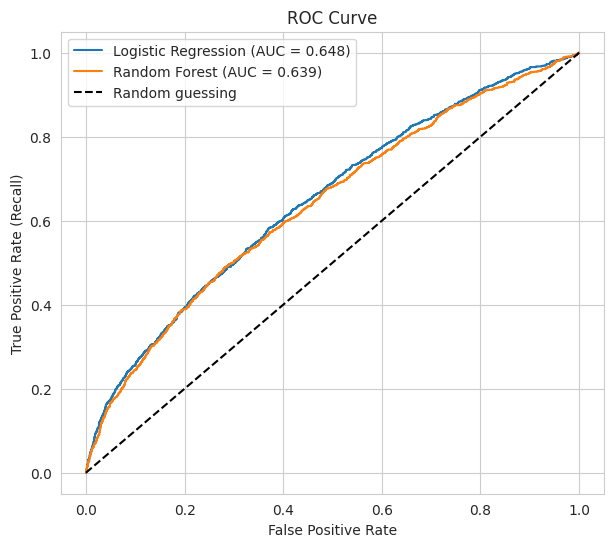

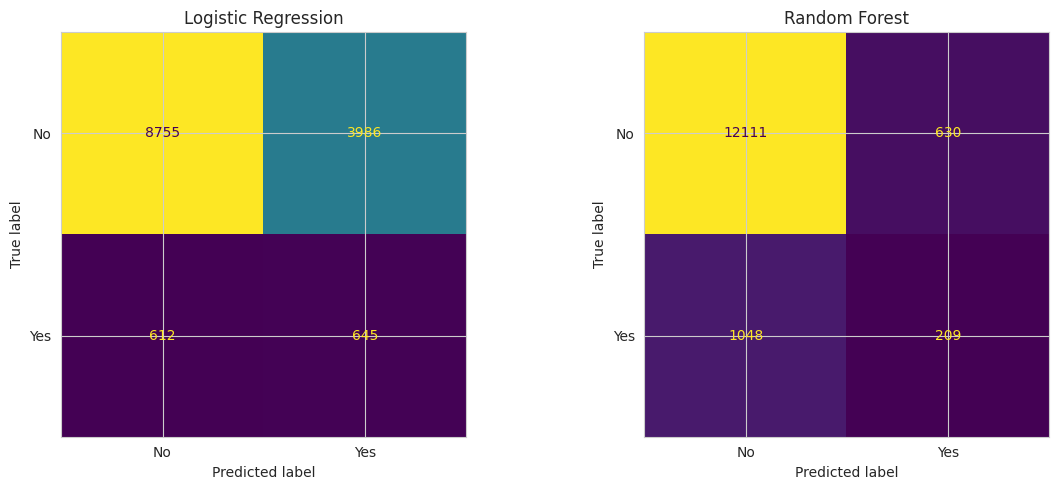

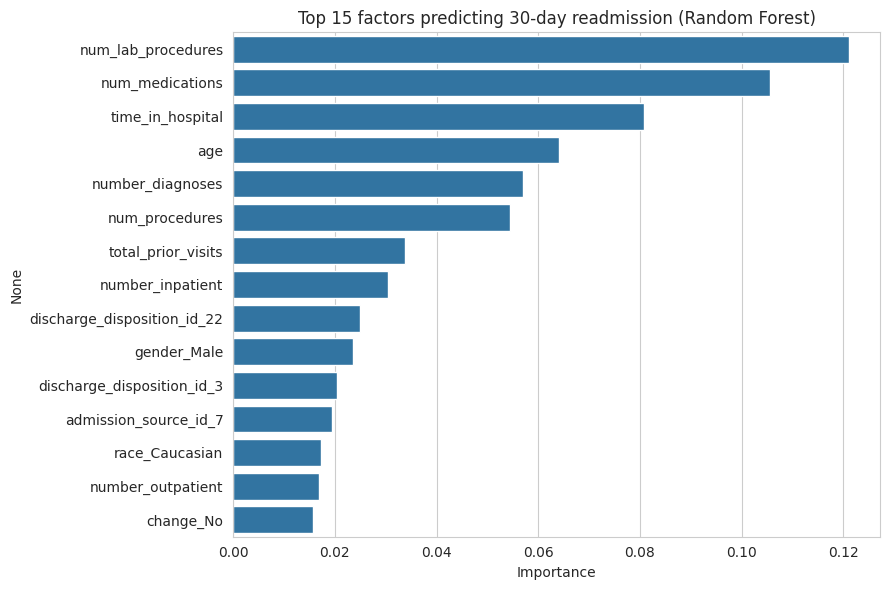


Top 10 features:
 num_lab_procedures             0.1211
num_medications                0.1056
time_in_hospital               0.0807
age                            0.0640
number_diagnoses               0.0570
num_procedures                 0.0545
total_prior_visits             0.0338
number_inpatient               0.0304
discharge_disposition_id_22    0.0250
gender_Male                    0.0235
dtype: float64


In [ ]:
# =========================================================
# Hospital Readmission Risk Prediction - FINAL (all-in-one)
# Pipeline + Interactive Predictor
# =========================================================

import os, io, zipfile, sqlite3, warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# ---------------------------------------------------------
# STEP 1: Download and load the dataset
# ---------------------------------------------------------
URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"

if not os.path.exists("diabetic_data.csv"):
    try:
        r = requests.get(URL, timeout=60)
        r.raise_for_status()
        zipfile.ZipFile(io.BytesIO(r.content)).extractall(".")
        print("Downloaded dataset.")
    except Exception as e:
        print("Auto-download failed:", e)
        print("Please upload diabetic_data.csv manually.")
        from google.colab import files
        files.upload()

df = pd.read_csv("diabetic_data.csv")
print("Shape:", df.shape)
print("\nTarget distribution:\n", df["readmitted"].value_counts())

# ---------------------------------------------------------
# STEP 2: SQL (SQLite) analysis
# ---------------------------------------------------------
conn = sqlite3.connect("hospital.db")
df.to_sql("encounters", conn, if_exists="replace", index=False)

q1 = """
SELECT readmitted, COUNT(*) AS patients,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM encounters), 2) AS pct
FROM encounters GROUP BY readmitted;
"""
print("\nSQL 1 - Readmission split:\n", pd.read_sql(q1, conn))

q2 = """
SELECT age, COUNT(*) AS total,
       SUM(CASE WHEN readmitted = '<30' THEN 1 ELSE 0 END) AS readmitted_30,
       ROUND(100.0 * SUM(CASE WHEN readmitted = '<30' THEN 1 ELSE 0 END) / COUNT(*), 2) AS rate_pct
FROM encounters GROUP BY age ORDER BY age;
"""
print("\nSQL 2 - Readmission rate by age group:\n", pd.read_sql(q2, conn))

q3 = """
SELECT number_inpatient AS prior_inpatient_visits, COUNT(*) AS total,
       ROUND(100.0 * SUM(CASE WHEN readmitted = '<30' THEN 1 ELSE 0 END) / COUNT(*), 2) AS rate_pct
FROM encounters GROUP BY number_inpatient
HAVING COUNT(*) > 100 ORDER BY number_inpatient;
"""
print("\nSQL 3 - Readmission rate by prior inpatient visits:\n", pd.read_sql(q3, conn))
conn.close()

# ---------------------------------------------------------
# STEP 3: Data cleaning
# ---------------------------------------------------------
df = df.replace("?", np.nan)

print("\nMissing % (top columns):")
print((df.isna().mean() * 100).sort_values(ascending=False).head(8).round(1))

df = df.drop(columns=["weight", "payer_code", "medical_specialty"])
df = df[~df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]   # died / hospice
df = df.drop_duplicates(subset="patient_nbr", keep="first")               # one visit per patient
df = df.drop(columns=["encounter_id", "patient_nbr", "diag_1", "diag_2", "diag_3"])

for col in ["race", "max_glu_serum", "A1Cresult"]:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown")
df["gender"] = df["gender"].replace("Unknown/Invalid", np.nan)
df = df.dropna(subset=["gender"])
print("\nShape after cleaning:", df.shape)

# ---------------------------------------------------------
# STEP 4: Target + EDA
# ---------------------------------------------------------
df["target"] = (df["readmitted"] == "<30").astype(int)
df = df.drop(columns=["readmitted"])
print("\nReadmission rate: {:.2f}%".format(df["target"].mean() * 100))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(x="target", data=df, ax=axes[0, 0])
axes[0, 0].set_title("Class balance (0 = No, 1 = Readmitted <30 days)")
sns.barplot(x="age", y="target", data=df, order=sorted(df["age"].unique()), ax=axes[0, 1])
axes[0, 1].set_title("Readmission rate by age group")
axes[0, 1].tick_params(axis="x", rotation=45)
sns.barplot(x="number_inpatient", y="target", data=df[df["number_inpatient"] <= 8], ax=axes[1, 0])
axes[1, 0].set_title("Readmission rate by prior inpatient visits")
sns.boxplot(x="target", y="num_medications", data=df, ax=axes[1, 1])
axes[1, 1].set_title("Number of medications vs readmission")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# STEP 5: Feature engineering
# ---------------------------------------------------------
age_map = {f"[{i}-{i+10})": i + 5 for i in range(0, 100, 10)}
df["age"] = df["age"].map(age_map)

for col in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    df[col] = df[col].astype(str)

df["total_prior_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]

X = pd.get_dummies(df.drop(columns=["target"]), drop_first=True)
y = df["target"]
print("\nFeature matrix shape:", X.shape)

# ---------------------------------------------------------
# STEP 6: Train / test split
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# ---------------------------------------------------------
# STEP 7: Train models
# ---------------------------------------------------------
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced"))
log_reg.fit(X_train, y_train)

rf = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=5,
    class_weight="balanced_subsample", n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

# ---------------------------------------------------------
# STEP 8: Evaluate
# ---------------------------------------------------------
models = {"Logistic Regression": log_reg, "Random Forest": rf}
plt.figure(figsize=(7, 6))
for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, proba)
    print("\n" + "=" * 55)
    print(name, "| ROC-AUC:", round(auc, 3))
    print("=" * 55)
    print(classification_report(y_test, pred, target_names=["Not readmitted", "Readmitted <30d"]))
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test)),
                           display_labels=["No", "Yes"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# STEP 9: Feature importance
# ---------------------------------------------------------
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 6))
sns.barplot(x=importances.values, y=importances.index)
plt.title("Top 15 factors predicting 30-day readmission (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
print("\nTop 10 features:\n", importances.head(10).round(4))

# =========================================================
# STEP 10: INTERACTIVE RISK PREDICTOR
# =========================================================
scaler = log_reg.named_steps["standardscaler"]
lr = log_reg.named_steps["logisticregression"]
baseline = X_train.median()      # "typical patient" for anything not entered

FRIENDLY = {
    "age": "Age", "time_in_hospital": "Days in hospital",
    "num_lab_procedures": "Lab tests done", "num_procedures": "Procedures done",
    "num_medications": "Number of medications", "number_outpatient": "Past outpatient visits",
    "number_emergency": "Past emergency visits", "number_inpatient": "Past inpatient admissions",
    "number_diagnoses": "Number of diagnoses", "total_prior_visits": "Total prior visits",
}

def set_category(row, col, value):
    for c in X.columns:
        if c.startswith(col + "_"):
            row[c] = 0
    target = f"{col}_{value}"
    if target in X.columns:
        row[target] = 1

style = {"description_width": "190px"}
lay = widgets.Layout(width="520px")

age = widgets.IntSlider(value=65, min=5, max=95, description="Age", style=style, layout=lay)
gender = widgets.Dropdown(options=["Female", "Male"], description="Gender", style=style, layout=lay)
days = widgets.IntSlider(value=4, min=1, max=14, description="Days in hospital", style=style, layout=lay)
inpatient = widgets.IntSlider(value=0, min=0, max=10, description="Past inpatient admissions", style=style, layout=lay)
emergency = widgets.IntSlider(value=0, min=0, max=10, description="Past emergency visits", style=style, layout=lay)
outpatient = widgets.IntSlider(value=0, min=0, max=10, description="Past outpatient visits", style=style, layout=lay)
meds = widgets.IntSlider(value=15, min=1, max=60, description="Number of medications", style=style, layout=lay)
labs = widgets.IntSlider(value=43, min=1, max=120, description="Lab tests done", style=style, layout=lay)
procs = widgets.IntSlider(value=1, min=0, max=6, description="Procedures done", style=style, layout=lay)
diags = widgets.IntSlider(value=7, min=1, max=16, description="Number of diagnoses", style=style, layout=lay)
admit_type = widgets.Dropdown(
    options=[("Emergency", "1"), ("Urgent", "2"), ("Elective (planned)", "3")],
    description="Admission type", style=style, layout=lay)
discharge = widgets.Dropdown(
    options=[("Discharged to home", "1"), ("Transferred to another hospital", "2"),
             ("Skilled nursing facility", "3"), ("Home with health service", "6")],
    description="Discharged to", style=style, layout=lay)
insulin = widgets.Dropdown(options=["No", "Steady", "Up", "Down"], description="Insulin", style=style, layout=lay)
med_change = widgets.Dropdown(options=[("Medication changed", "Ch"), ("No change", "No")],
                              description="Medication change", style=style, layout=lay)
diabetes_med = widgets.Dropdown(options=["Yes", "No"], description="On diabetes medication", style=style, layout=lay)
a1c = widgets.Dropdown(options=["Unknown", "None", "Norm", ">7", ">8"], description="A1C test result", style=style, layout=lay)

button = widgets.Button(description="Predict Readmission Risk", button_style="primary",
                        layout=widgets.Layout(width="260px", height="40px"))
out = widgets.Output()

def predict(_):
    row = baseline.copy()
    row["age"] = age.value
    row["time_in_hospital"] = days.value
    row["number_inpatient"] = inpatient.value
    row["number_emergency"] = emergency.value
    row["number_outpatient"] = outpatient.value
    row["num_medications"] = meds.value
    row["num_lab_procedures"] = labs.value
    row["num_procedures"] = procs.value
    row["number_diagnoses"] = diags.value
    row["total_prior_visits"] = inpatient.value + emergency.value + outpatient.value

    set_category(row, "gender", gender.value)
    set_category(row, "admission_type_id", admit_type.value)
    set_category(row, "discharge_disposition_id", discharge.value)
    set_category(row, "insulin", insulin.value)
    set_category(row, "change", med_change.value)
    set_category(row, "diabetesMed", diabetes_med.value)
    set_category(row, "A1Cresult", a1c.value)

    patient = pd.DataFrame([row[X.columns]])
    lr_prob = log_reg.predict_proba(patient)[0, 1]
    rf_prob = rf.predict_proba(patient)[0, 1]

    z = scaler.transform(patient)[0]
    contrib = pd.Series(lr.coef_[0] * z, index=X.columns)
    up = contrib.sort_values(ascending=False).head(4)
    down = contrib.sort_values().head(3)

    def label(name):
        if name in FRIENDLY:
            return f"{FRIENDLY[name]} = {patient[name].iloc[0]:.0f}"
        return name.replace("_", " ")

    if lr_prob >= 0.5:
        verdict, color, level = "YES - likely to be readmitted within 30 days", "#c0392b", "HIGH RISK"
    elif lr_prob >= 0.35:
        verdict, color, level = "NO (borderline) - moderate chance", "#e67e22", "MODERATE RISK"
    else:
        verdict, color, level = "NO - unlikely to be readmitted within 30 days", "#27ae60", "LOW RISK"

    up_html = "".join(f"<li>{label(n)} <span style='color:#c0392b'>(raises risk)</span></li>"
                      for n, v in up.items() if v > 0)
    down_html = "".join(f"<li>{label(n)} <span style='color:#27ae60'>(lowers risk)</span></li>"
                        for n, v in down.items() if v < 0)

    with out:
        clear_output()
        display(HTML(f"""
        <div style="font-family:Arial; border:2px solid {color}; border-radius:10px; padding:18px; max-width:620px">
          <h2 style="margin:0; color:{color}">{verdict}</h2>
          <p style="font-size:30px; margin:8px 0"><b>{lr_prob*100:.1f}%</b> readmission risk score
             <span style="font-size:16px; color:{color}">({level})</span></p>
          <p style="margin:0; color:#555">Second opinion (Random Forest): <b>{rf_prob*100:.1f}%</b></p>
          <hr>
          <b>Why this result?</b>
          <p style="margin:6px 0 2px">Factors pushing risk UP:</p>
          <ul style="margin:0">{up_html or "<li>None significant</li>"}</ul>
          <p style="margin:8px 0 2px">Factors pushing risk DOWN:</p>
          <ul style="margin:0">{down_html or "<li>None significant</li>"}</ul>
          <hr>
          <small style="color:#777">Educational project, not medical advice. Inputs you don't set use
          typical values from the training data.</small>
        </div>"""))

button.on_click(predict)

display(widgets.VBox([
    widgets.HTML("<h2>Hospital Readmission Risk Predictor</h2>"),
    age, gender, days, inpatient, emergency, outpatient, meds, labs, procs, diags,
    admit_type, discharge, insulin, med_change, diabetes_med, a1c,
    button, out
]))